### Import Libraries

In [57]:
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from numpy.random import randn, seed

rng = np.random.default_rng(42)

### Generate Data

In [58]:
def moons(n=300, noise=0.15):
    """
    Two interleaving half circles. 
    Not linearly separable.
    """
    n1 = n // 2
    t1 = rng.uniform(0, np.pi, n1)
    t2 = rng.uniform(0, np.pi, n - n1)
    a = np.c_[np.cos(t1), np.sin(t1)]
    b = np.c_[1 - np.cos(t2), 0.5 - np.sin(t2)]
    X = np.vstack([a, b]) + rng.normal(0, noise, (n, 2))
    y = np.r_[np.zeros(n1), np.ones(n - n1)].astype(int)
    return X, y

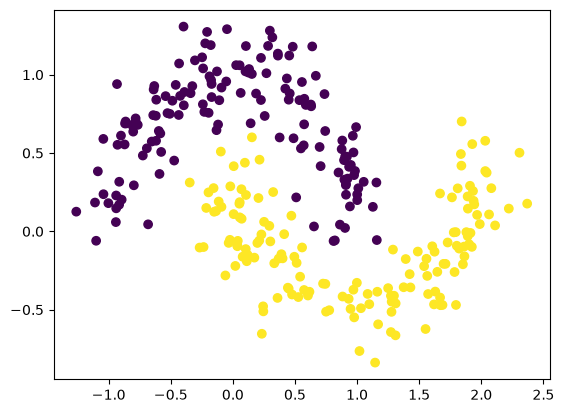

In [59]:
X, y = moons()
plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y)

In [60]:
print(X.shape, y.shape)

N = X.shape[0]
X_reshaped = X.reshape(N, 2, 1)
y_reshaped = y.reshape(N, 1, 1)

print(X_reshaped.shape, y_reshaped.shape)

(300, 2) (300,)
(300, 2, 1) (300, 1, 1)


In [61]:
idx = rng.permutation(N)

N_train = int(0.7 * N)
train_indices = np.sort(idx[:N_train])
test_indices = np.sort(idx[N_train:])

X_train, y_train = X_reshaped[train_indices], y_reshaped[train_indices]
X_test,  y_test  = X_reshaped[test_indices],  y_reshaped[test_indices]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(210, 2, 1) (210, 1, 1)
(90, 2, 1) (90, 1, 1)


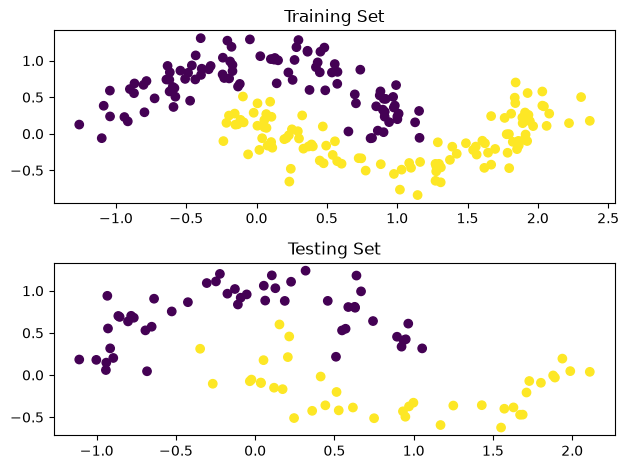

In [62]:
plt.figure()

plt.subplot(2,1,1)
plt.scatter(X_train[:,0,0], X_train[:,1,0], c=y_train)
plt.title("Training Set")

plt.subplot(2,1,2)
plt.scatter(X_test[:,0,0], X_test[:,1,0], c=y_test)
plt.title("Testing Set")

plt.tight_layout()

In [63]:
# Define activation function
s  = lambda z: 1 / (1 + np.exp(-z))
ds = lambda x: s(x) * (1 - s(x))

In [76]:
# Initialize weights randomly using Uniform distribution
# Uniform distribution selects random number between low and high
# size = (i, m, n) means i sample(s) of m-by-n matrix

In = 2                  # Number of input(s)
L1 = 20                 # Number of neurons in Layer-1
L2 = 20                 # Number of neurons in Layer-2
Out = 1                 # Number of neurons in output layer

np.random.seed(0)               # select seed for reproducible results
W1 = np.random.uniform(low=-1, high=1, size=(1,  L1,  In))
W2 = np.random.uniform(low=-1, high=1, size=(1,  L2,  L1))
W3 = np.random.uniform(low=-1, high=1, size=(1,  Out, L2))

In [77]:
# Initialize biases randomly using Uniform distribution

# 8 outputs by the first layer
b1 = np.random.uniform(low=-1, high=1, size=(1, L1, 1))
# 16 outputs by the second layer
b2 = np.random.uniform(low=-1, high=1, size=(1, L2, 1))
# 1 output by the third layer
b3 = np.random.uniform(low=-1, high=1, size=(1, Out, 1))

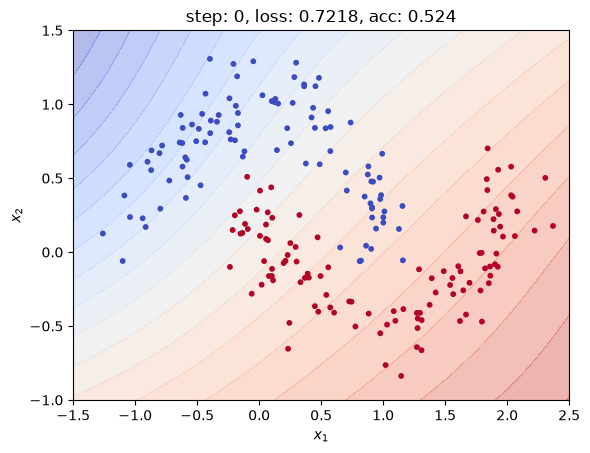

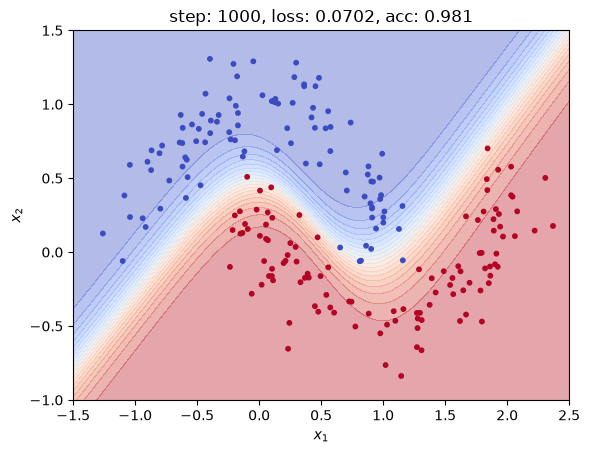

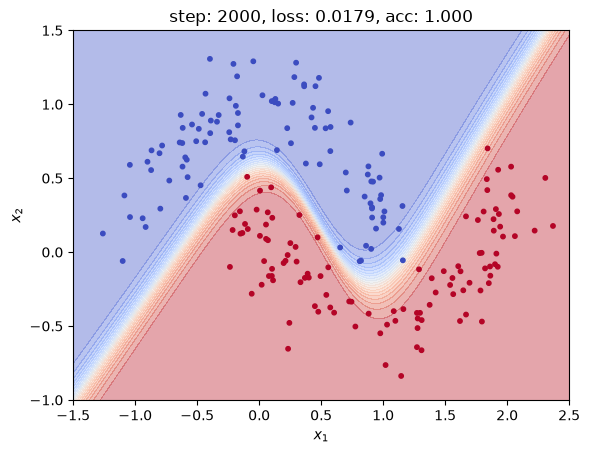

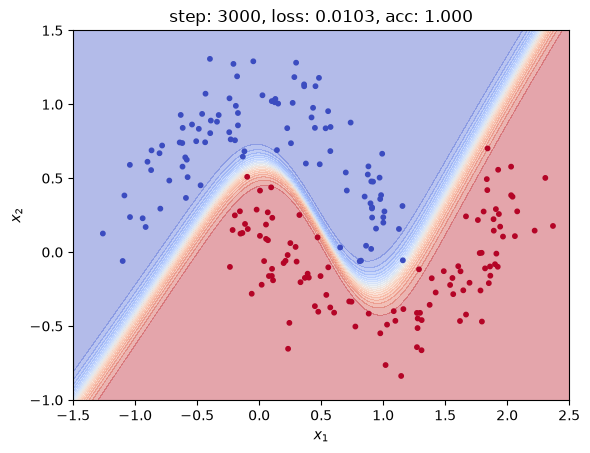

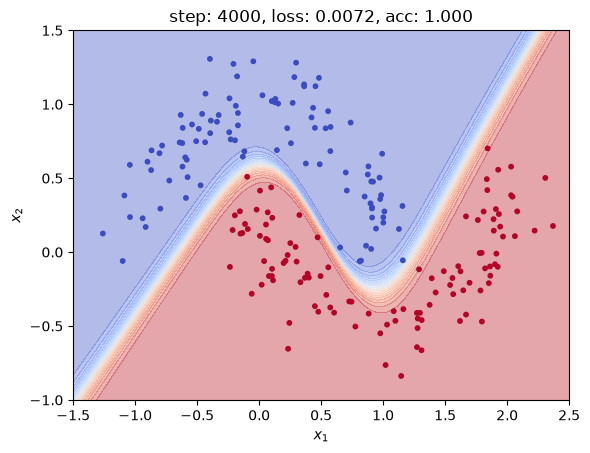

In [78]:
epochs = 5000           # iterate over whole data 1000 times
lr = 0.5               # learning rate

for i in range(epochs):

    # Forward pass
    h = W1 @ X_train + b1
    g = W2 @ s(h) + b2
    f = W3 @ s(g) + b3
    p = s(f)

    # Back-propagate
    diag_g = ds(g)*np.expand_dims(np.eye(L2),0)
    diag_h = ds(h)*np.expand_dims(np.eye(L1),0)

    dldf = p - y_train
    dldg = (dldf @ W3) @ diag_g
    dldh = (dldg @ W2) @ diag_h

    dW1 = (dldh * X_train).transpose(0, 2, 1) 
    dW2 = (dldg * s(h)).transpose(0, 2, 1)  
    dW3 = (dldf * s(g)).transpose(0, 2, 1) 

    db1 = dldh.transpose(0, 2, 1)
    db2 = dldg.transpose(0, 2, 1)
    db3 = dldf.transpose(0, 2, 1) 

    # get mean gradient
    dW1 = np.mean(dW1, 0, keepdims=True)
    dW2 = np.mean(dW2, 0, keepdims=True)
    dW3 = np.mean(dW3, 0, keepdims=True)
    db1 = np.mean(db1, 0, keepdims=True)
    db2 = np.mean(db2, 0, keepdims=True)
    db3 = np.mean(db3, 0, keepdims=True)

    # Gradient descent
    W1 -= lr * dW1
    W2 -= lr * dW2
    W3 -= lr * dW3
    b1 -= lr * db1
    b2 -= lr * db2
    b3 -= lr * db3

    # if i % 1000 == 0:
    #     l = -np.mean(y_train * np.log(p + 1e-9) + (1 - y_train) * np.log(1 - p + 1e-9))
    #     acc = np.mean((p > 0.5) == y_train)

    #     plt.figure()
    #     plt.title(f"step: {i}, loss: {l:.4f}, acc: {acc:.3f}")
    #     plt.scatter(X_train[:, 0, 0], X_train[:, 1, 0], c=(p[:, 0, 0] > 0.5), cmap="coolwarm")
    #     plt.xlabel("$x_1$")
    #     plt.ylabel("$x_2$")
    #     plt.show()
            
    if i % 1000 == 0:
        eps = 1e-9
        l = -np.mean(y_train * np.log(p + eps) + (1 - y_train) * np.log(1 - p + eps))
        acc = np.mean((p > 0.5) == y_train)

        # decision boundary on a grid
        xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
        grid = np.c_[xx.ravel(), yy.ravel()].reshape(-1, 2, 1)
        hg = W1 @ grid + b1
        gg = W2 @ s(hg) + b2
        pg = 1 / (1 + np.exp(-(W3 @ s(gg) + b3)))

        plt.figure()
        plt.title(f"step: {i}, loss: {l:.4f}, acc: {acc:.3f}")
        plt.contourf(xx, yy, pg.reshape(xx.shape), levels=20, cmap="coolwarm", alpha=0.4)
        plt.scatter(X_train[:, 0, 0], X_train[:, 1, 0], c=y_train[:, 0, 0], cmap="coolwarm", s=10)
        plt.xlabel("$x_1$")
        plt.ylabel("$x_2$")
        plt.show()

train loss: 0.0056   acc: 1.000
test  loss: 0.0348   acc: 0.989


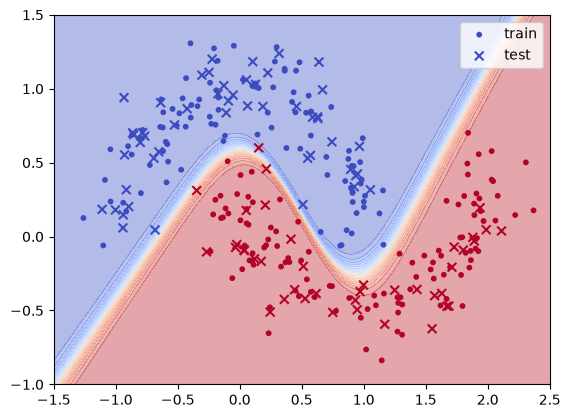

In [75]:
p_train = s(W3 @ s(W2 @ s(W1 @ X_train + b1) + b2) + b3)
p_test  = s(W3 @ s(W2 @ s(W1 @ X_test  + b1) + b2) + b3)

def bce(p, y): return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

print(f"train loss: {bce(p_train, y_train):.4f}   acc: {np.mean((p_train > 0.5) == y_train):.3f}")
print(f"test  loss: {bce(p_test,  y_test):.4f}   acc: {np.mean((p_test  > 0.5) == y_test):.3f}")

pg = s(W3 @ s(W2 @ s(W1 @ grid + b1) + b2) + b3)

plt.figure()
plt.contourf(xx, yy, pg.reshape(xx.shape), levels=20, cmap="coolwarm", alpha=0.4)
plt.scatter(X_train[:, 0, 0], X_train[:, 1, 0], c=y_train[:, 0, 0], cmap="coolwarm", s=10, label="train")
plt.scatter(X_test[:, 0, 0], X_test[:, 1, 0], c=y_test[:, 0, 0], cmap="coolwarm", s=40, marker="x", label="test")
plt.legend()
plt.show()